In [19]:
import pandas as pd
import numpy as np
from pathlib import Path as FilePath

## Loading Dataset

In [20]:
dataset_path = FilePath("../datasets/zr7vgbcyr2-1/metadata.csv")

df = pd.read_csv(dataset_path)

df.head()


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


## metadata inspection

In [21]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (2298, 26)

Column Names:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

Data Types:


patient_id                 str
lesion_id                int64
smoke                   object
drink                   object
background_father          str
background_mother          str
age                      int64
pesticide               object
gender                     str
skin_cancer_history     object
cancer_history          object
has_piped_water         object
has_sewage_system       object
fitspatrick            float64
region                     str
diameter_1             float64
diameter_2             float64
diagnostic                 str
itch                       str
grew                       str
hurt                       str
changed                    str
bleed                      str
elevation                  str
img_id                     str
biopsed                   bool
dtype: object


First 5 Rows:


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


## Image aur Data Quality Analysis

In [22]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

# Dataset images folder
IMAGE_DIR = Path(
    r"C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vgbcyr2-1\images"
)

image_files = list(IMAGE_DIR.rglob("*"))
image_files = [
    p for p in image_files
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
]

dimensions = []
unreadable = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            dimensions.append({
                "filename": path.name,
                "width": img.width,
                "height": img.height
            })

    except (OSError, ValueError, UnidentifiedImageError) as exc:
        unreadable.append({
            "filename": path.name,
            "error": str(exc)
        })

dimensions_df = pd.DataFrame(dimensions)
unreadable_df = pd.DataFrame(unreadable)

print("Total image files:", len(image_files))
print("Readable images:", len(dimensions_df))
print("Unreadable images:", len(unreadable_df))

display(dimensions_df.head())
display(dimensions_df[["width", "height"]].describe())
display(unreadable_df.head())

Total image files: 2298
Readable images: 2298
Unreadable images: 0


,filename,width,height
0,PAT_100_393_595.png,394,394
1,PAT_100_393_898.png,221,221
2,PAT_101_1041_651.png,1131,1131
3,PAT_101_1041_658.png,741,740
4,PAT_101_1041_898.png,1795,1796


,width,height
count,2298.000000,2298.000000
mean,933.679721,933.605309
std,534.598513,534.668475
min,147.000000,147.000000
25%,528.000000,527.250000
50%,779.500000,779.500000
75%,1219.250000,1218.750000
max,3474.000000,3476.000000


""


In [23]:
REPORT_DIR = Path(
    r"C:\Users\Sarthak\Desktop\DermAI\data\reports"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

dimensions_df.to_csv(
    REPORT_DIR / "image_dimensions.csv",
    index=False
)

unreadable_df.to_csv(
    REPORT_DIR / "unreadable_images.csv",
    index=False
)

print("Reports saved to:", REPORT_DIR)



Reports saved to: C:\Users\Sarthak\Desktop\DermAI\data\reports


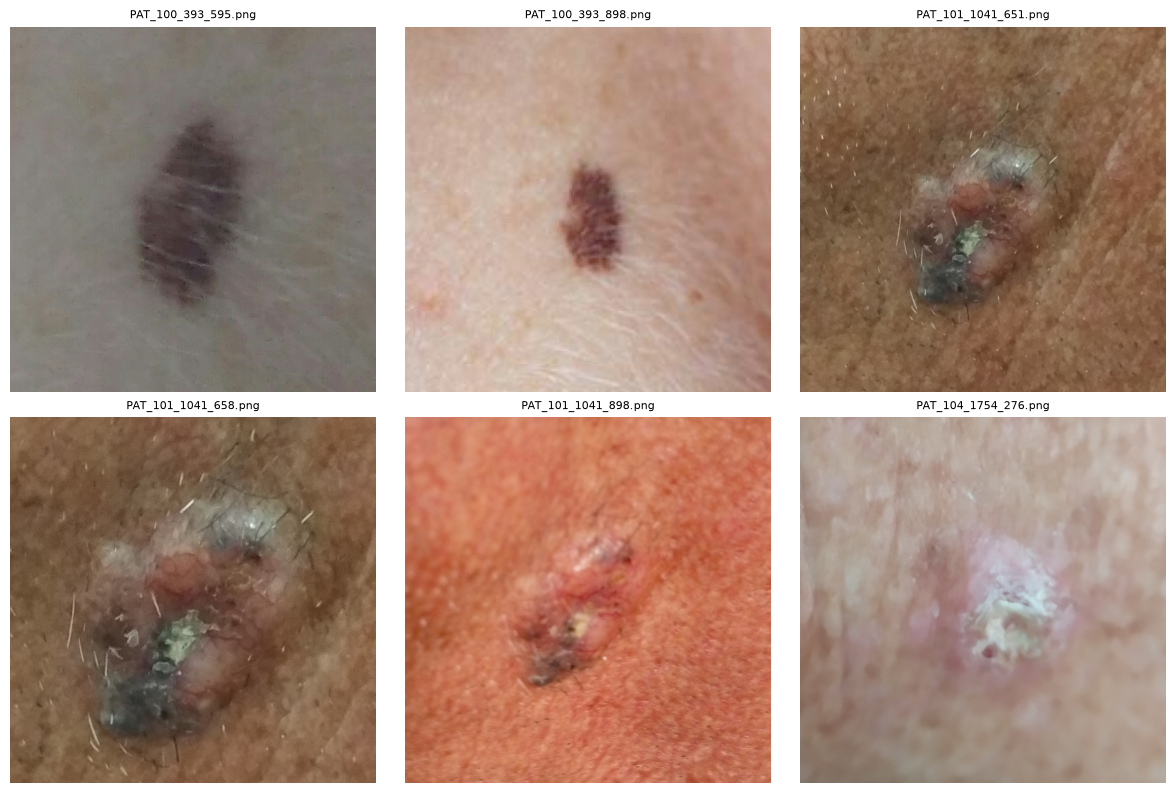

In [24]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

sample_paths = dimensions_df["filename"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, filename in zip(axes.flat, sample_paths):
    matches = list(IMAGE_DIR.rglob(filename))

    if matches:
        with Image.open(matches[0]) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            ax.imshow(img)

        ax.set_title(filename, fontsize=8)
    else:
        ax.set_title(f"Not found: {filename}", fontsize=8)

    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for path in IMAGE_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        try:
            file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_groups[file_hash].append(path.name)
        except OSError as exc:
            print("Could not read:", path.name, exc)

duplicate_groups = [
    filenames
    for filenames in hash_groups.values()
    if len(filenames) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))

for group in duplicate_groups[:10]:
    print(group)

Exact duplicate groups: 15
['PAT_202_307_424.png', 'PAT_202_308_721.png']
['PAT_302_650_477.png', 'PAT_302_651_529.png']
['PAT_311_666_191.png', 'PAT_311_667_416.png']
['PAT_38_1002_34.png', 'PAT_38_1003_68.png']
['PAT_38_1002_668.png', 'PAT_38_1003_226.png']
['PAT_419_2767_323.png', 'PAT_419_833_148.png']
['PAT_528_3072_615.png', 'PAT_528_993_589.png']
['PAT_56_86_479.png', 'PAT_56_88_274.png']
['PAT_570_1084_637.png', 'PAT_570_1085_344.png']
['PAT_570_1084_939.png', 'PAT_570_1085_429.png']


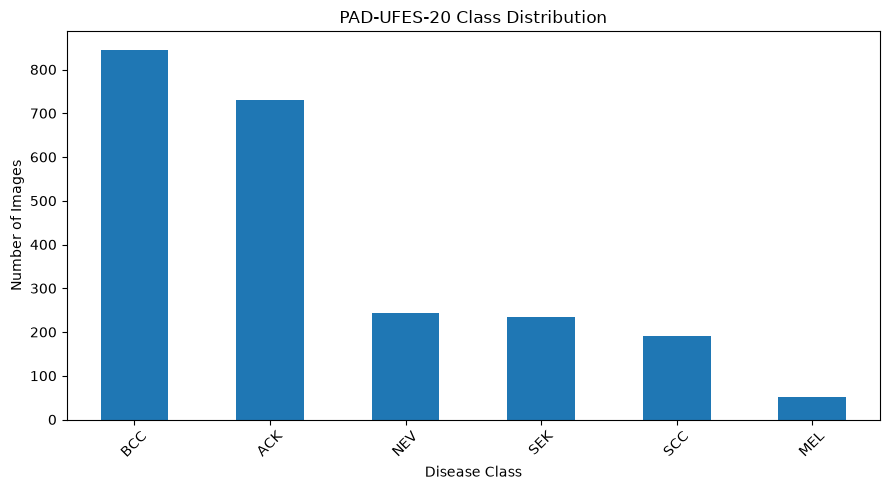

Reports saved in: C:\Users\Sarthak\Desktop\DermAI\data\reports
Files: ['class_distribution.png', 'image_dimensions.csv', 'unreadable_images.csv']


In [27]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Users\Sarthak\Desktop\DermAI")
REPORT_DIR = PROJECT_ROOT / "data" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save image dimensions
dimensions_df.to_csv(
    REPORT_DIR / "image_dimensions.csv",
    index=False
)

# 2. Save unreadable-image report
unreadable_df.to_csv(
    REPORT_DIR / "unreadable_images.csv",
    index=False
)

# 3. Save class distribution chart
class_counts = df["diagnostic"].value_counts()

plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("PAD-UFES-20 Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Reports saved in:", REPORT_DIR)
print("Files:", [p.name for p in REPORT_DIR.iterdir()])